<p align="center">
<a href="https://colab.research.google.com/github/md-ryhan-uddin/ai-lab-experiments/blob/main/experiment_07.ipynb">
    <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

<a href="https://kaggle.com/kernels/welcome?src=https://github.com/md-ryhan-uddin/ai-lab-experiments/blob/main/experiment_07.ipynb">
    <img src="https://kaggle.com/static/images/open-in-kaggle.svg" alt="Open In Kaggle" height="20"/>
</a>
</p>

## **Experiment 07:** Training and Performance Analysis of Feedforward Neural Networks using the Backpropagation Algorithm



## **Source Code**

Run the following cells one by one. Read the output after each cell and add comments in your own words where instructed by your teacher.

**Tip:** Do not only run the notebook. Try changing the number of hidden units, the activation function, or the batch size, and observe how the learning curves and confusion matrix change.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # suppress verbose TensorFlow startup logs

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

tf.keras.utils.set_random_seed(42)
np.random.seed(42)
plt.style.use("seaborn-v0_8-whitegrid")
%matplotlib inline

print("Setup complete. You can start the experiment.")

Setup complete. You can start the experiment.


In [2]:
# Load the Digits dataset and scale pixel values

digits = load_digits()
X = digits.data.astype("float32") / 16.0
y = digits.target
y_one_hot = tf.keras.utils.to_categorical(y, num_classes=10)

print("Shape:", X.shape)
print("Class counts:\n", np.bincount(y))
print("Pixel value range after scaling: [{:.2f}, {:.2f}]".format(X.min(), X.max()))

Shape: (1797, 64)
Class counts:
 [178 182 177 183 181 182 181 179 174 180]
Pixel value range after scaling: [0.00, 1.00]


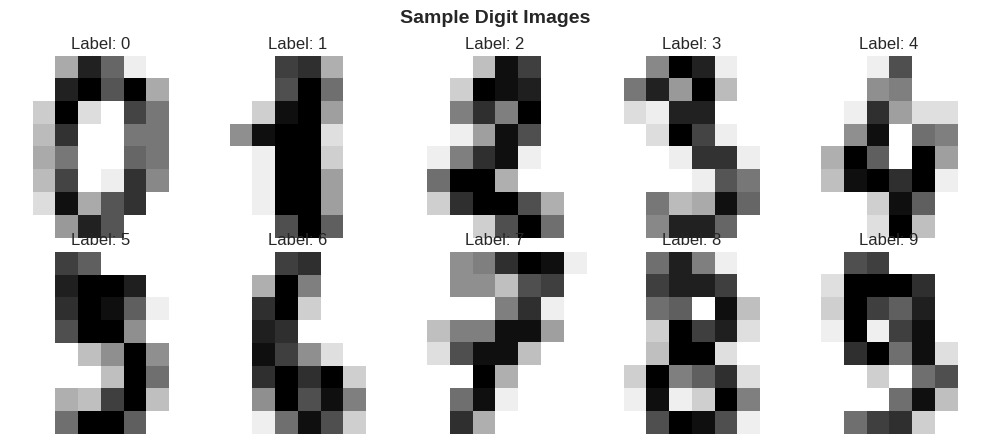

In [3]:
# Visualize Sample Digit Images

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(digits.images[i], cmap="gray_r")
    ax.set_title(f"Label: {digits.target[i]}")
    ax.axis("off")

plt.suptitle("Sample Digit Images", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [4]:
# Train / Validation / Test Split

X_train_full, X_test, y_train_full, y_test, y_train_full_int, y_test_int = train_test_split(
    X, y_one_hot, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)
X_train, X_val, y_train, y_val, y_train_int, y_val_int = train_test_split(
    X_train_full, y_train_full, y_train_full_int,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full_int,
)

print("Train shape     :", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape      :", X_test.shape)

Train shape     : (1149, 64)
Validation shape: (288, 64)
Test shape      : (360, 64)


In [5]:
# Build the Feedforward Neural Network

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64,)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,226 (67.29 KB)

 Trainable params: 17,226 (67.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Train the Network with Early Stopping (Backpropagation)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)],
)

print(f"Training finished after {len(history.history['loss'])} epochs.")

Training finished after 50 epochs.


In [7]:
# Evaluate on the Test Set

test_probabilities = model.predict(X_test, verbose=0)
test_predictions = np.argmax(test_probabilities, axis=1)
test_true = np.argmax(y_test, axis=1)

test_accuracy = accuracy_score(test_true, test_predictions)
print(f"Test Accuracy : {test_accuracy:.4f}")
print(classification_report(test_true, test_predictions, target_names=[str(i) for i in range(10)]))

Test Accuracy : 0.9806
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.94      0.94      0.94        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       0.97      1.00      0.99        36
           8       0.94      0.94      0.94        35
           9       0.97      0.97      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



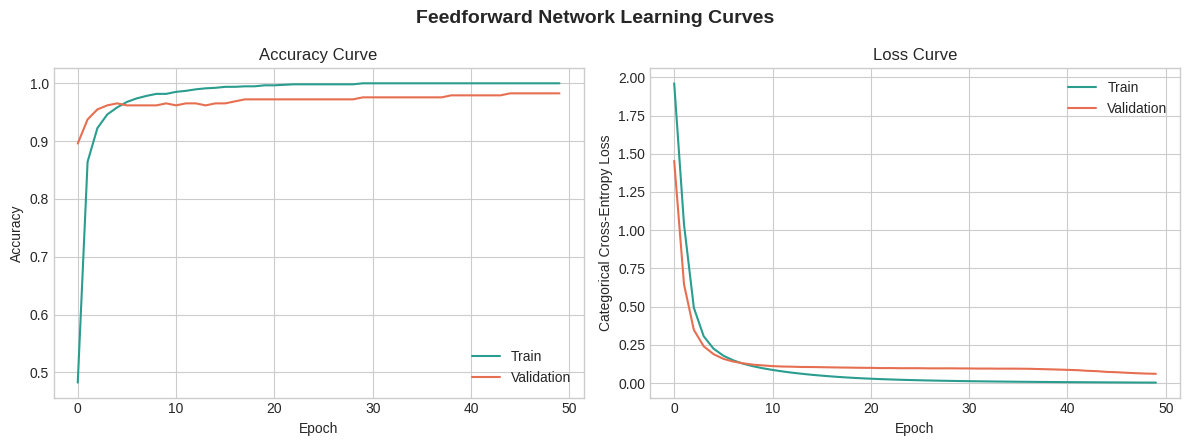

In [8]:
# Training vs Validation Accuracy and Loss Curves

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(history.history["accuracy"], label="Train", color="#2a9d8f")
axes[0].plot(history.history["val_accuracy"], label="Validation", color="#e76f51")
axes[0].set_title("Accuracy Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train", color="#2a9d8f")
axes[1].plot(history.history["val_loss"], label="Validation", color="#e76f51")
axes[1].set_title("Loss Curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Categorical Cross-Entropy Loss")
axes[1].legend()

plt.suptitle("Feedforward Network Learning Curves", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

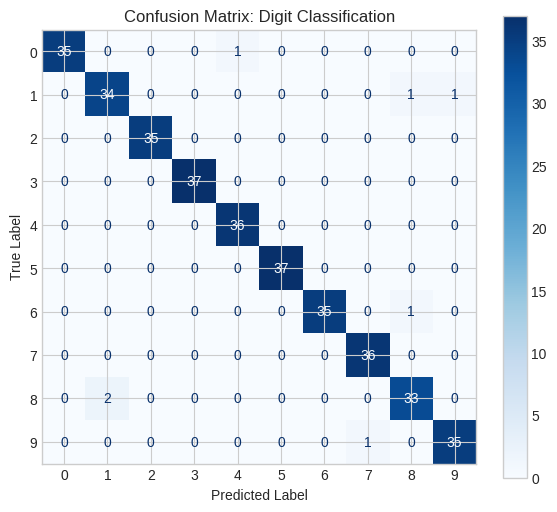

In [9]:
# Confusion Matrix

cm = confusion_matrix(test_true, test_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[str(i) for i in range(10)]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(cmap="Blues", ax=ax, colorbar=True, values_format="d")

plt.title("Confusion Matrix: Digit Classification")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

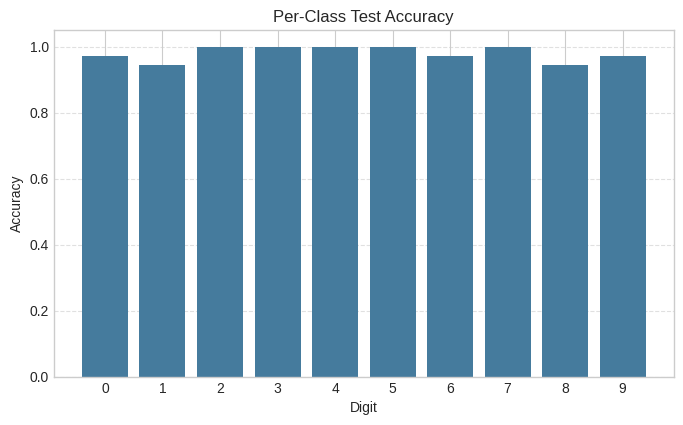

In [10]:
# Per-Class Accuracy

per_class_accuracy = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(8, 4.5))
plt.bar(range(10), per_class_accuracy, color="#457b9d")

plt.xlabel("Digit")
plt.ylabel("Accuracy")
plt.title("Per-Class Test Accuracy")
plt.xticks(range(10))
plt.ylim(0, 1.05)
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()

Correctly classified : 353 / 360
Misclassified         : 7 / 360


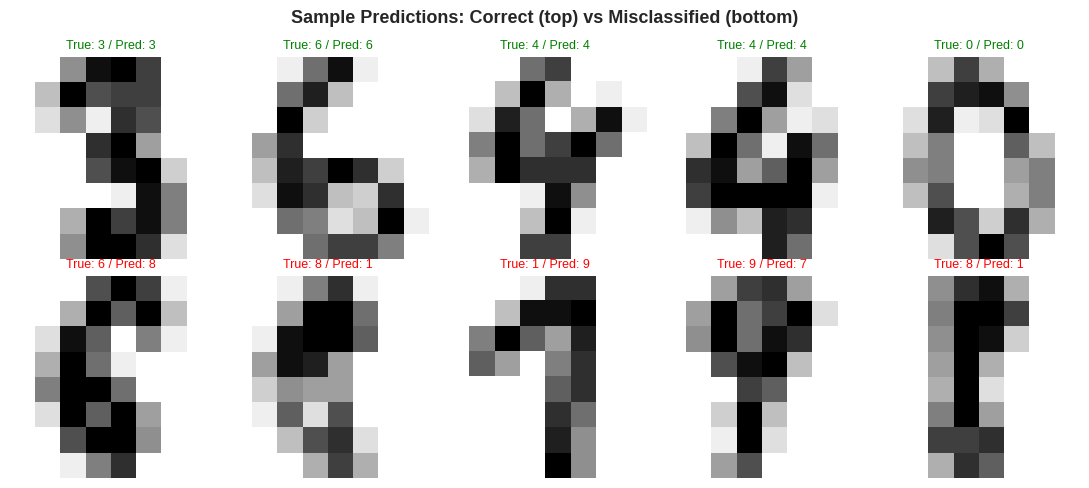

In [11]:
# Visualize Correct and Misclassified Predictions

misclassified = np.where(test_predictions != test_true)[0]
correct = np.where(test_predictions == test_true)[0]

print(f"Correctly classified : {len(correct)} / {len(test_true)}")
print(f"Misclassified         : {len(misclassified)} / {len(test_true)}")

sample_correct = np.random.choice(correct, size=5, replace=False)
sample_wrong = misclassified[:5] if len(misclassified) >= 5 else misclassified

fig, axes = plt.subplots(2, 5, figsize=(11, 5))

for ax, idx in zip(axes[0], sample_correct):
    ax.imshow(X_test[idx].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"True: {test_true[idx]} / Pred: {test_predictions[idx]}", fontsize=9, color="green")
    ax.axis("off")

for ax, idx in zip(axes[1], sample_wrong):
    ax.imshow(X_test[idx].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"True: {test_true[idx]} / Pred: {test_predictions[idx]}", fontsize=9, color="red")
    ax.axis("off")

for ax in axes[1][len(sample_wrong):]:
    ax.axis("off")

axes[0, 0].set_ylabel("Correct", fontsize=11)
axes[1, 0].set_ylabel("Misclassified", fontsize=11)

plt.suptitle("Sample Predictions: Correct (top) vs Misclassified (bottom)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## **Experimental Tasks**

Below are the implementations to systematically test the tasks suggested in your instructions. Run these cells sequentially to observe and analyze the differences.

### **Task 1: Change Hidden Units**
We reduce the structure from `128 -> 64` to `64 -> 32` units and compare its test accuracy with our original network.

In [17]:
model_small = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64,)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax"),
])

model_small.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

history_small = model_small.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)],
)

test_acc_small = accuracy_score(test_true, np.argmax(model_small.predict(X_test, verbose=0), axis=1))
print(f"Original Model Test Accuracy: {test_accuracy:.4f}")
print(f"Smaller Model (64/32) Test Accuracy: {test_acc_small:.4f}")

Original Model Test Accuracy: 0.9806
Smaller Model (64/32) Test Accuracy: 0.9722


### **Task 2: Try `tanh` Activation**
We evaluate the model using `tanh` in place of `relu` activation for the hidden layers.

In [18]:
model_tanh = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64,)),
    tf.keras.layers.Dense(128, activation="tanh"),
    tf.keras.layers.Dense(64, activation="tanh"),
    tf.keras.layers.Dense(10, activation="softmax"),
])

model_tanh.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

history_tanh = model_tanh.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)],
)

print(f"ReLU model converged in: {len(history.history['loss'])} epochs")
print(f"Tanh model converged in: {len(history_tanh.history['loss'])} epochs")

ReLU model converged in: 50 epochs
Tanh model converged in: 50 epochs


### **Task 3: Add Dropout Layers**
We introduce a standard `Dropout` rate of `0.2` after each hidden layer to evaluate generalization and the gap between training and validation accuracy.

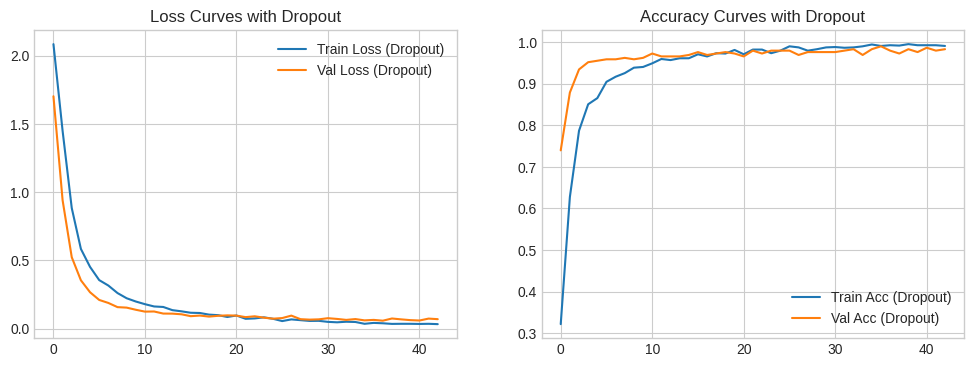

In [19]:
model_dropout = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64,)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation="softmax"),
])

model_dropout.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

history_dropout = model_dropout.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)],
)

# Plot the effect of dropout
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history_dropout.history["loss"], label="Train Loss (Dropout)")
ax[0].plot(history_dropout.history["val_loss"], label="Val Loss (Dropout)")
ax[0].set_title("Loss Curves with Dropout")
ax[0].legend()

ax[1].plot(history_dropout.history["accuracy"], label="Train Acc (Dropout)")
ax[1].plot(history_dropout.history["val_accuracy"], label="Val Acc (Dropout)")
ax[1].set_title("Accuracy Curves with Dropout")
ax[1].legend()
plt.show()

### **Task 4: Train Without Early Stopping**
Let's run training for 100 fixed epochs to visualize learning curve saturation or overfitting.

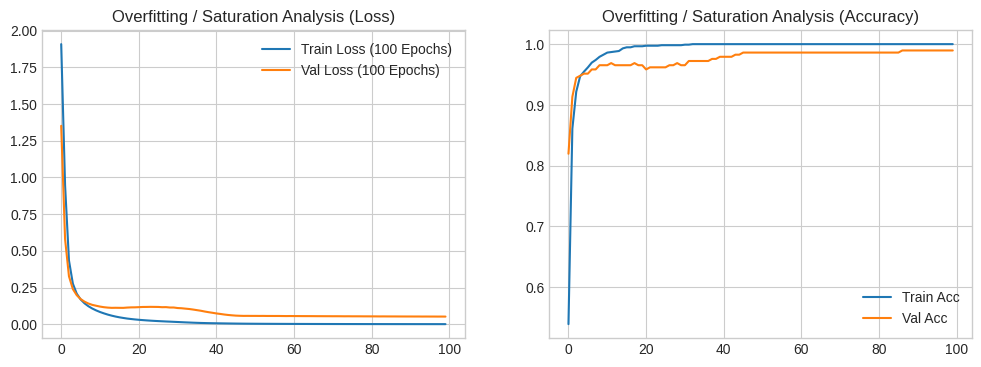

In [20]:
model_no_es = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64,)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax"),
])

model_no_es.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

history_no_es = model_no_es.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=0,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_no_es.history["loss"], label="Train Loss (100 Epochs)")
axes[0].plot(history_no_es.history["val_loss"], label="Val Loss (100 Epochs)")
axes[0].legend()
axes[0].set_title("Overfitting / Saturation Analysis (Loss)")

axes[1].plot(history_no_es.history["accuracy"], label="Train Acc")
axes[1].plot(history_no_es.history["val_accuracy"], label="Val Acc")
axes[1].legend()
axes[1].set_title("Overfitting / Saturation Analysis (Accuracy)")
plt.show()

### **Task 5: Adapt to the Wine Dataset**
We import, scale, and split the `load_wine` multiclass dataset, setting up a model configured with correct input (13) and output (3) dimensions.

In [21]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

wine = load_wine()
X_w = StandardScaler().fit_transform(wine.data)
y_w = tf.keras.utils.to_categorical(wine.target, num_classes=3)

X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_w, y_w, test_size=0.2, random_state=42, stratify=wine.target
)

model_wine = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_w.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax"),
])

model_wine.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

history_wine = model_wine.fit(
    X_train_w, y_train_w,
    validation_split=0.15,
    epochs=40,
    batch_size=16,
    verbose=0,
)

wine_eval = model_wine.evaluate(X_test_w, y_test_w, verbose=0)
print(f"Wine Dataset Test Accuracy: {wine_eval[1]:.4f}")

Wine Dataset Test Accuracy: 0.9722
